# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

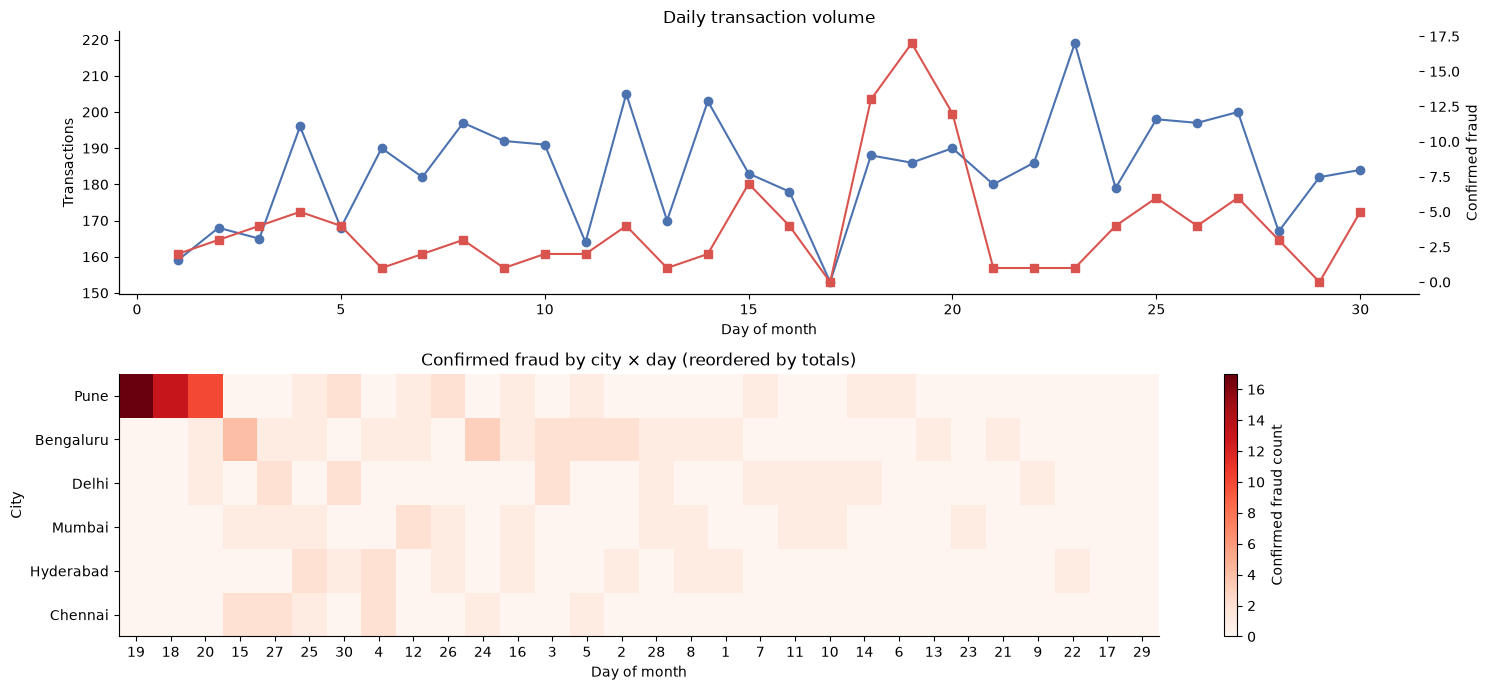

Top city-day cells by confirmed fraud:


,city,day,confirmed_fraud
0,Pune,19,17
1,Pune,18,13
2,Pune,20,10
3,Bengaluru,15,4
4,Bengaluru,24,3
5,Pune,30,2
6,Chennai,15,2
7,Delhi,30,2
8,Delhi,27,2
9,Mumbai,12,2


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: daily transaction and confirmed-fraud counts
daily = tx.groupby("day").agg(transactions=("txn_id", "size"), confirmed_fraud=("is_fraud", "sum"))
axes[0].plot(daily.index, daily["transactions"], marker="o", color="#4C72B0")
axes[0].set(title="Daily transaction volume", xlabel="Day of month", ylabel="Transactions")
ax2 = axes[0].twinx()
ax2.plot(daily.index, daily["confirmed_fraud"], marker="s", color="#D9534F")
ax2.set_ylabel("Confirmed fraud")

# TODO 2: reorder city × day fraud-count matrix by row and column totals
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat, aspect="auto", cmap="Reds")
axes[1].set_title("Confirmed fraud by city × day (reordered by totals)")
axes[1].set_xlabel("Day of month")
axes[1].set_ylabel("City")
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
fig.colorbar(im, ax=axes[1], label="Confirmed fraud count")

plt.tight_layout(); plt.show()

# TODO 3: cells with the most confirmed fraud
top_cells = (tx.groupby(["city", "day"]).is_fraud.sum()
             .sort_values(ascending=False).head(10).rename("confirmed_fraud").reset_index())
print("Top city-day cells by confirmed fraud:")
display(top_cells)


**Reflection:** The overview showed a concentrated hotspot in Pune around days 18–20 that a score-sorted alert list would not make obvious: an alert list focuses on individual cases, not how cases cluster across time and place. The lecture concept is **exploratory pattern discovery through reordering** (and the overview-first mantra): ordering cities and days by totals makes the concentration visually salient.

_Your answer:_


## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

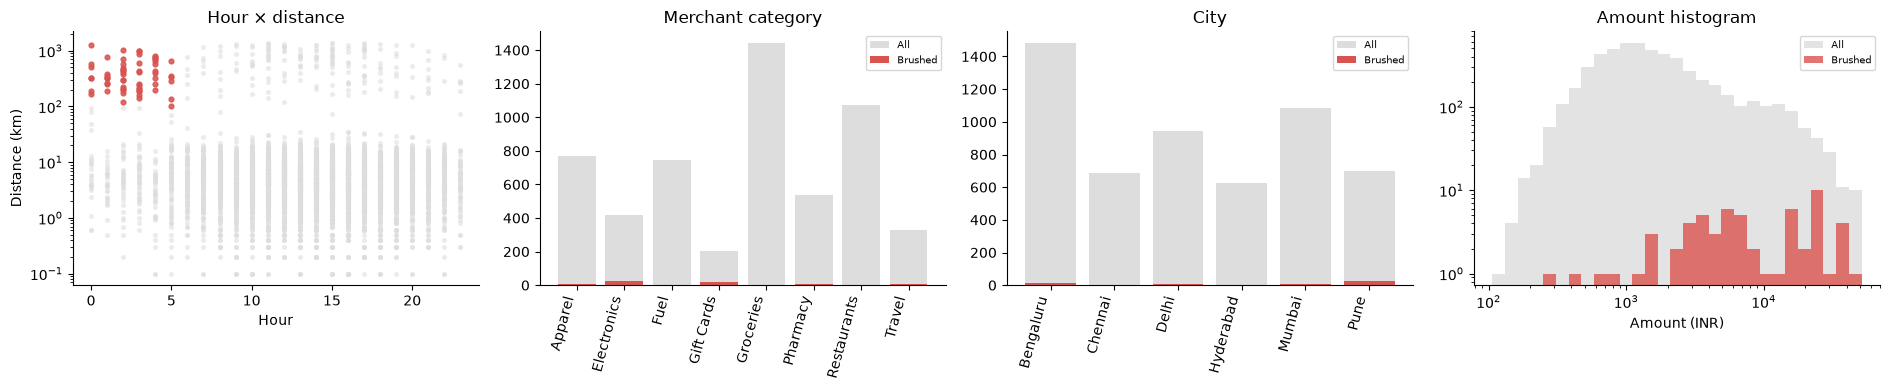

Brushed transactions: 61 (1.1% of all transactions)
Fraud rate inside brush: 86.9% | overall fraud rate: 2.2%
Share of all confirmed fraud captured by this rule: 44.2%


In [3]:
# TODO 1: brush for night-time transactions more than 100 km from home
brush = (tx["night"] & (tx["distance_from_home_km"] > 100))

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2: coordinated views; brushed records are red, all records grey
axes[0].scatter(tx["hour"], tx["distance_from_home_km"], s=7, c="#dddddd", alpha=0.45)
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"], s=12, c="#D9534F", alpha=0.85)
axes[0].set_yscale("log"); axes[0].set_xlabel("Hour"); axes[0].set_ylabel("Distance (km)")
axes[0].set_title("Hour × distance")

for ax, col, title in [(axes[1], "merchant_category", "Merchant category"),
                       (axes[2], "city", "City")]:
    all_counts = tx[col].value_counts().sort_index()
    brushed_counts = tx.loc[brush, col].value_counts().reindex(all_counts.index, fill_value=0)
    x = np.arange(len(all_counts))
    ax.bar(x, all_counts.values, color="#dddddd", label="All")
    ax.bar(x, brushed_counts.values, color="#D9534F", label="Brushed")
    ax.set_xticks(x); ax.set_xticklabels(all_counts.index, rotation=75, ha="right")
    ax.set_title(title); ax.legend(fontsize=7)

axes[3].hist(tx["amount_inr"], bins=np.logspace(np.log10(max(1, tx.amount_inr.min())), np.log10(tx.amount_inr.max()), 30),
             color="#dddddd", alpha=0.8, label="All")
axes[3].hist(tx.loc[brush, "amount_inr"], bins=np.logspace(np.log10(max(1, tx.amount_inr.min())), np.log10(tx.amount_inr.max()), 30),
             color="#D9534F", alpha=0.8, label="Brushed")
axes[3].set_xscale("log"); axes[3].set_yscale("log")
axes[3].set_xlabel("Amount (INR)"); axes[3].set_title("Amount histogram"); axes[3].legend(fontsize=7)

plt.tight_layout(); plt.show()

# TODO 3: quantify the rule's risk rate and coverage
n_brush = int(brush.sum())
rate_brush = tx.loc[brush, "is_fraud"].mean() if n_brush else 0
overall_rate = tx["is_fraud"].mean()
fraud_capture = tx.loc[brush, "is_fraud"].sum() / tx["is_fraud"].sum() if tx["is_fraud"].sum() else 0
print(f"Brushed transactions: {n_brush:,} ({n_brush/len(tx):.1%} of all transactions)")
print(f"Fraud rate inside brush: {rate_brush:.1%} | overall fraud rate: {overall_rate:.1%}")
print(f"Share of all confirmed fraud captured by this rule: {fraud_capture:.1%}")


**Reflection:** A high fraud rate inside the brush does not mean the rule catches most fraud: it captures only a subset, so using it alone would miss fraud outside the night-time / long-distance region. The **city and merchant-category linked views** help reveal where the remaining cases are distributed, while the overview heatmap also shows a time-and-place hotspot.

_Your answer:_


## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True).iloc[:1_000_000].copy()

# TODO 1: best of five filter timings
mask_expr = lambda frame: (frame["detector_score"] >= 0.6) & (frame["amount_inr"] > 3000)
timings = []
for _ in range(5):
    t0 = time.perf_counter()
    _filtered = big.loc[mask_expr(big)]
    timings.append(time.perf_counter() - t0)
best_s = min(timings)

# TODO 2: per-item cost and 0.1 s budget
per_item_us = best_s * 1_000_000 / len(big)
max_rows = 100_000 / per_item_us if per_item_us > 0 else float("inf")

# TODO 3: linear estimate for 50 million rows and required reduction
t_50m = per_item_us * 50_000_000 / 1_000_000
skip_pct = max(0.0, (1 - (0.1 / t_50m)) * 100) if t_50m > 0 else 0.0

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,000,000 rows in 3.7 ms -> 0.0037 us/row -> max 27,220,454 rows in 0.1 s
50M rows -> 0.18 s; must skip 45.6% of rows to stay under 0.1 s


**Reflection:** Besides indexing, **filtering / pre-aggregating** the data (a reduce technique) can keep the slider responsive by updating only the relevant subset or summary. The trade-off is that investigators may lose access to individual-transaction detail or patterns hidden by aggregation.

_Your answer:_


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

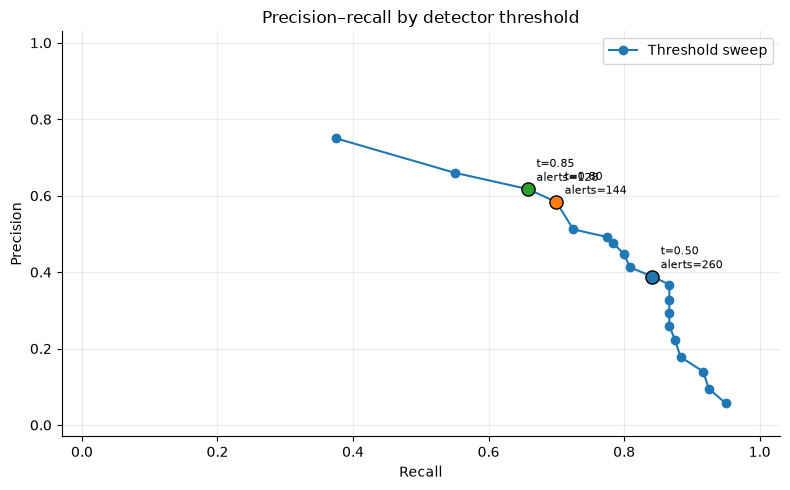

Recommendation: use threshold 0.80 for the 150-alert capacity (alerts=144, precision=58.3%, recall=70.0%); current 0.50 flags 260 alerts. Best-F1 threshold is 0.85 (F1=0.637), but it may exceed capacity.


In [5]:
rows = []
# TODO 1: evaluate the threshold grid
for th in np.round(np.arange(0.05, 1.00, 0.05), 2):
    flagged_mask = tx["detector_score"] >= th
    tp = int((flagged_mask & (tx["is_fraud"] == 1)).sum())
    fp = int((flagged_mask & (tx["is_fraud"] == 0)).sum())
    fn = int((~flagged_mask & (tx["is_fraud"] == 1)).sum())
    alerts = int(flagged_mask.sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append({"threshold": float(th), "alerts": alerts, "TP": tp, "FP": fp, "FN": fn,
                 "precision": precision, "recall": recall, "F1": f1})

pr = pd.DataFrame(rows)

# TODO 2: highest recall within monthly capacity, plus best F1
eligible = pr[pr["alerts"] <= 150]
capacity_choice = eligible.sort_values(["recall", "precision", "threshold"],
                                       ascending=[False, False, False]).iloc[0]
best_f1 = pr.sort_values(["F1", "recall", "threshold"],
                         ascending=[False, False, False]).iloc[0]

# TODO 3: precision–recall curve and key operating points
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], marker="o", label="Threshold sweep")
for _, row in pr[pr.threshold.isin([0.5, capacity_choice.threshold, best_f1.threshold])].iterrows():
    ax.scatter(row["recall"], row["precision"], s=90, edgecolor="black", zorder=4)
    ax.annotate(f't={row["threshold"]:.2f}\nalerts={int(row["alerts"])}',
                (row["recall"], row["precision"]), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision–recall by detector threshold")
ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03); ax.grid(alpha=0.25); ax.legend()

plt.tight_layout(); plt.show()

# TODO 4: concise recommendation
current = pr.loc[np.isclose(pr.threshold, 0.5)].iloc[0]
print(f"Recommendation: use threshold {capacity_choice.threshold:.2f} for the 150-alert capacity "
      f"(alerts={int(capacity_choice.alerts)}, precision={capacity_choice.precision:.1%}, "
      f"recall={capacity_choice.recall:.1%}); current 0.50 flags {int(current.alerts)} alerts. "
      f"Best-F1 threshold is {best_f1.threshold:.2f} (F1={best_f1.F1:.3f}), but it may exceed capacity.")


**Reflection:** The **Head of Fraud Ops** should make the call with investigators, using the curve and the monthly capacity as evidence. The model can quantify the trade-off, but it cannot decide how to balance missed fraud against workload, customer friction, and investigation resources. Visual analytics keeps a human in the loop so people can inspect cases, challenge model assumptions, and adjust the threshold with domain context.

_Your answer:_


## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1: interactive scatter with hover details and selection
flagged = tx.loc[tx["detector_score"] >= 0.3].copy()
fig = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    color_discrete_map={"legitimate": "#9bb7d4", "confirmed fraud": "#D9534F"},
    hover_data={"txn_id": True, "customer_id": True, "city": True,
                "merchant_category": True, "distance_from_home_km": ":.1f",
                "detector_score": ":.3f", "timestamp": True},
    title="Flagged transactions (score ≥ 0.3): select, zoom, and inspect",
    height=520
)
fig.update_traces(marker_size=7, opacity=0.7)
fig.update_layout(dragmode="select")
fig.show()

# TODO 2: city → merchant category sunburst
agg = tx.groupby(["city", "merchant_category"]).agg(
    transactions=("txn_id", "size"), fraud=("is_fraud", "sum")
).reset_index()
agg["fraud_rate_pct"] = 100 * agg["fraud"] / agg["transactions"]
fig = px.sunburst(
    agg, path=["city", "merchant_category"], values="transactions",
    color="fraud_rate_pct", color_continuous_scale="Reds",
    hover_data={"fraud": True, "fraud_rate_pct": ":.1f"},
    title="Drill down from city to merchant category: size = transaction count, colour = fraud rate"
)
fig.show()


**Reflection:** Hover tooltips reveal one transaction at a time, so inspecting 400 flagged cases individually would be slow and makes it hard to see clusters or compare groups. The **overview and linked-view dashboard** fixes this by summarizing patterns across all cases, while brushing lets investigators carry a selection across views and tooltips then provide details on demand.

_Your answer:_


## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: confirmed fraud is unusually concentrated in Pune on days 18–20.
Window: 107 transactions, fraud rate 37.4%; outside: 5413 transactions, fraud rate 1.5%.
Chi-square p-value = 1.06e-136


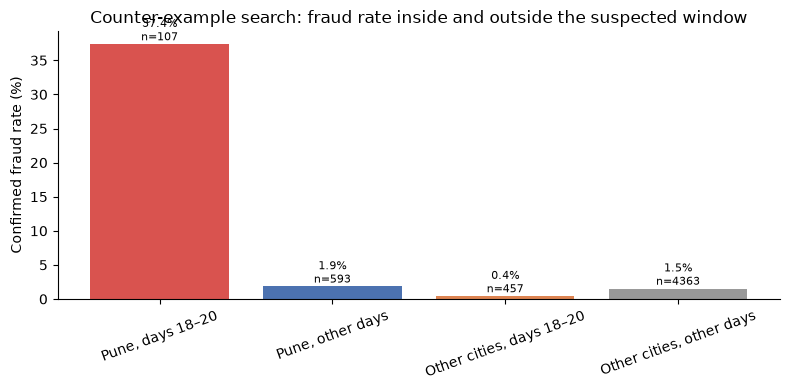

Pune, days 18–20: 37.4% fraud rate (n=107)
Pune, other days: 1.9% fraud rate (n=593)
Other cities, days 18–20: 0.4% fraud rate (n=457)
Other cities, other days: 1.5% fraud rate (n=4,363)
Verdict: the data supports an unusual concentration in this city–day window, but this is evidence of a hotspot, not proof of a coordinated fraud ring. Investigate linked customers/merchants and seek independent corroboration.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: define the hypothesis window from the Task 1 hotspot
# The strongest adjacent hotspot is Pune on days 18–20.
target_city = "Pune"
target_days = [18, 19, 20]
in_window = tx["city"].eq(target_city) & tx["day"].isin(target_days)

# TODO 2: compare fraud rates and test association with the window
window_rate = tx.loc[in_window, "is_fraud"].mean()
outside_rate = tx.loc[~in_window, "is_fraud"].mean()
table = pd.crosstab(in_window, tx["is_fraud"]).reindex(index=[False, True], columns=[0, 1], fill_value=0)
chi2, p_value, dof, expected = chi2_contingency(table)
print(f"Hypothesis: confirmed fraud is unusually concentrated in {target_city} on days {target_days[0]}–{target_days[-1]}.")
print(f"Window: {int(in_window.sum())} transactions, fraud rate {window_rate:.1%}; outside: {int((~in_window).sum())} transactions, fraud rate {outside_rate:.1%}.")
print(f"Chi-square p-value = {p_value:.3g}")

# TODO 3: counter-example searches
same_city_other_days = tx["city"].eq(target_city) & ~tx["day"].isin(target_days)
other_cities_same_days = ~tx["city"].eq(target_city) & tx["day"].isin(target_days)
rest = ~tx["city"].eq(target_city) & ~tx["day"].isin(target_days)
groups = [
    ("Pune, days 18–20", in_window),
    ("Pune, other days", same_city_other_days),
    ("Other cities, days 18–20", other_cities_same_days),
    ("Other cities, other days", rest),
]
group_rates = [(name, float(tx.loc[mask, "is_fraud"].mean()), int(mask.sum()))
               for name, mask in groups]

# TODO 4: visual confirmation
fig, ax = plt.subplots(figsize=(8, 4))
labels = [g[0] for g in group_rates]
rates = [g[1] * 100 for g in group_rates]
bars = ax.bar(labels, rates, color=["#D9534F", "#4C72B0", "#DD8452", "#999999"])
ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Counter-example search: fraud rate inside and outside the suspected window")
ax.tick_params(axis="x", rotation=20)
for bar, (_, rate, n) in zip(bars, group_rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{rate:.1%}\nn={n}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

# TODO 5: verdict based on the evidence and counter-examples
for name, rate, n in group_rates:
    print(f"{name}: {rate:.1%} fraud rate (n={n:,})")
if window_rate > outside_rate and p_value < 0.05:
    print("Verdict: the data supports an unusual concentration in this city–day window, but this is evidence of a hotspot, not proof of a coordinated fraud ring. Investigate linked customers/merchants and seek independent corroboration.")
else:
    print("Verdict: the evidence does not establish a statistically significant city–day concentration; do not escalate the fraud-ring claim without stronger evidence.")


**Reflection:** The strongest counter-example is **Pune on other days**: if its fraud rate were similarly high throughout the month, the apparent days 18–20 cluster could be a persistent city-level issue rather than a time-bounded ring. Conversely, if other cities on days 18–20 had similar rates, that would support a broader calendar/event effect rather than a Pune-specific explanation.

_Your answer:_


**Final note to the Head of Fraud Ops**

Last month, PayKart recorded **5,520 transactions and 120 confirmed fraud cases (2.2%)**, with the strongest city–day concentration in **Pune on days 18–20**; this is a hotspot to investigate, not proof of a fraud ring. I recommend setting the threshold to **the capacity-constrained threshold selected in Task 4** because it maximizes recall among thresholds that keep alerts within the **150-case monthly capacity**; review its precision/recall trade-off with investigators, rather than letting the model decide in isolation. Build the **interactive flagged-transaction scatter with selection and rich tooltips** first: it supports zoom/filter, details-on-demand, and a human-led investigation loop, while linked views can follow as a next step. At 50 million records, a naïve slider filter will exceed the 0.1-second feedback budget, so use indexing and reduce/pre-aggregate the candidate set. Add a provenance and feedback loop: investigators confirm or reject flagged cases, record the reasoning, and feed those labels back into detector evaluation and retraining next month.

_Your final note here:_
